In [1]:
from scipy.optimize import newton
from scipy.optimize import fsolve
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class AircraftConfig:
    def __init__(self, aircraft_parameters, configuration, hybridization_level, payload, desired_range, initial_guess):
        self.configuration = configuration  # 'VTOL', 'STOL', 'CTOL'
        self.hybridization_level = hybridization_level  # 0 to 1, where 0 is fully electric
        self.payload = payload  # Payload in kg
        self.desired_range = desired_range  # Desired range in km
        self.params = aircraft_parameters
        self.mtow = None  # Maximum Take-Off Weight
        self.initial_guess = initial_guess
        self.number_go_arounds = 1
        self.duration_cruise = (self.desired_range*1000/self.params['cruise_speed'])/3600

        # Initialize additional attributes to be calculated


    def calculate_power_requirements(self):
        self.thrust = 9.8*self.mtow # Newtons
        self.disk_loading = self.params['disk_loading']
        self.propeller_area = self.mtow/self.params['disk_loading']
        self.c_D = self.params['c_D0'] + self.params['C_L']**2/(np.pi * self.params['AR_wing'] * self.params['oswald_number'])
        self.Drag = (1/2) * self.params['air_density'] * self.params['cruise_speed']**2 * self.params['wing_area'] * self.c_D

        if self.configuration == 'VTOL':
            self.power_takeoff = self.thrust**(3/2)/(self.params['figure_merit']*(2*self.params['air_density']*self.propeller_area)**(1/2))
            self.power_climb = self.power_takeoff * (self.params['vertical_velocity_climb']/(2*self.params['induced_velocity_hover']) + ((self.params['vertical_velocity_climb']/(2*self.params['induced_velocity_hover']))**2 + 1)**(1/2))
            self.power_cruise = 1/self.params['propeller_efficiency'] * self.Drag * self.params['cruise_speed']
            self.power_descent = self.power_takeoff
            self.power_go_around = self.power_climb
            self.power_landing = self.power_takeoff
        elif self.configuration == 'STOL':
            #add the other phases
            self.power_cruise
        elif self.configuration == 'CTOL':
            self.power_cruise

    def calculate_energy_requirements(self):
        self.energy_takeoff = self.power_takeoff * self.params['duration_takeoff']
        self.energy_climb = self.power_climb * self.params['duration_climb']
        self.energy_cruise = self.power_cruise * self.duration_cruise
        self.energy_descent = self.power_descent * self.params['duration_descent']
        self.energy_go_around = self.number_go_arounds * self.power_go_around * self.params['duration_go_around']
        self.energy_landing = self.power_landing * self.params['duration_landing']

        self.total_energy_requirement = self.energy_takeoff + self.energy_climb + self.energy_cruise + self.energy_descent + self.energy_landing

        self.energy_distribution = {'Energy Takeoff': self.energy_takeoff,
            'Energy Climb': self.energy_climb,
            'Energy Cruise': self.energy_cruise,
            'Energy Descent': self.energy_descent,
            'Energy Go-Around': self.energy_go_around,
            'Energy Landing': self.energy_landing}

    def energy_system_mass_calculation(self):
        if self.configuration == 'VTOL':
            self.battery_mass = (self.total_energy_requirement * (1 + self.params['SoCmin'])) / (self.params['battery_specific_energy_density'] * self.params['battery_system_efficiency'])*(1 - self.hybridization_level)
            # Assuming fuel has a specific energy of 12 kWh/kg (approx. for Jet-A fuel) and turbine_efficiency
            self.fuel_mass = self.total_energy_requirement * self.hybridization_level / (self.params['fuel_specific_energy'] * 1000 * self.params['turbine_efficiency'])
            #change here for piston engine
            self.turbine_mass = self.power_takeoff * self.hybridization_level/3310  # P*gt = 3.31kW/kg by Finger.
        elif self.configuration == 'STOL':
            pass
        elif self.configuration == 'CTOL':
            pass

        self.mass_energy_system = self.battery_mass + self.fuel_mass + self.turbine_mass

    def propulsion_system_mass_calculation(self):
        self.propeller_area = self.mtow/self.params['disk_loading']
        self.propeller_diameter = np.sqrt(4*self.propeller_area/(self.params['number_motors'] * np.pi))
        self.mass_motors = self.power_takeoff/(3360*0.95) # EM mass eq: 5.92 kW/kg from Finger
        #self.mass_motors = 0.165*(self.power_climb*(1 + self.params['power_margin']))/self.params['number_motors']
        self.mass_propellers = 0.144 * (self.propeller_diameter * self.power_takeoff/(1000) * self.params['number_blades_propeller']**0.5)**0.782

        #self.mass_propulsion_system = self.mass_motors + self.mass_propellers
        self.mass_propulsion_system = 700

    def airframe_system_mass_calculation(self):
        self.mass_fuselage = 14.86*self.mtow**0.144 * (self.params['fuselage_length']/self.params['maximum_fuselage_section_perimeter'])**0.778 * self.params['fuselage_length']**0.383 * self.params['number_ocupants']**0.455
        self.mass_wing = 0.04674*self.mtow**0.397 * self.params['wing_area']**0.360 * self.params['wing_efficiency']**0.397 * self.params['AR_wing']**1.712
        self.mass_horizontal_tail = ((3.184*self.mtow**0.887 * self.params['horizontal_tail_area']**0.101 * self.params['AR_horizontal_tail']**0.101)/(174.04* self.params['root_chord_horizontal_tail']**0.223))
        self.mass_vertical_tail = ((1.68*self.mtow**0.567 * self.params['vertical_tail_area']**1.249 * self.params['AR_vertical_tail']**0.482)/(639.95*self.params['root_chord_vertical_tail']**0.747 * (np.cos(self.params['vertical_tail_quarter_chord_seet_angle']))**0.882))
        self.mass_landing_gear = 0.054 * self.params['landing_gear_length']**0.501*(self.mtow*self.params['landing_gear_efficiency'])**0.684

        self.mass_airframe_system = self.mass_fuselage + self.mass_wing + self.mass_horizontal_tail + self.mass_vertical_tail + self.mass_landing_gear

    def calculate_all_masses(self):
        # Assuming you have methods like these implemented:
        self.propulsion_system_mass_calculation()
        self.airframe_system_mass_calculation()
        self.energy_system_mass_calculation()

        # Now define mass_components as a dictionary of all calculated mass parts
        self.mass_components = {
            'Propulsion System': self.mass_propulsion_system,
            'Airframe System': self.mass_airframe_system,
            'Energy System': self.mass_energy_system,
            'Payload': self.payload
            # Add other components as needed
        }

    def mtow_balance(self, mtow):
        # Calculate the masses based on mtow. These methods must be defined.
        self.mtow = mtow  # Update mtow temporarily for the calculations
        self.calculate_power_requirements()
        self.calculate_energy_requirements()
        self.calculate_all_masses()

        # The balance equation
        return mtow - (self.payload + self.mass_energy_system + self.mass_propulsion_system + self.mass_airframe_system)

    def solve_for_mtow(self):
        # Initial guess for MTOW
        guess = self.initial_guess

        # Use scipy.optimize.newton to find the root of mtow_balance
        mtow_solution = newton(self.mtow_balance, guess)

        # Update self.mtow with the solution
        self.mtow = mtow_solution
        print(f"Estimated MTOW: {self.mtow} kg")

        return self.mtow

    def visualize_mass_distribution(self):
        # Calculate the total mass for the title.
        total_mass = sum(self.mass_components.values())

        # Sort the mass components in descending order for the pie chart.
        sorted_mass_components = dict(sorted(self.mass_components.items(), key=lambda item: item[1], reverse=True))

        labels = sorted_mass_components.keys()
        sizes = sorted_mass_components.values()

        # Define a custom autopct function to show the percentage and mass value.
        def make_autopct(values):
            def my_autopct(pct):
                val = int(round(pct*total_mass/100.0))
                return f'{pct:.1f}%\n({val:d} kg)'
            return my_autopct

        fig, ax = plt.subplots()
        wedges, texts, autotexts = ax.pie(sizes, labels=labels, autopct=make_autopct(sizes),
                                          startangle=90, counterclock=False)

        plt.setp(autotexts, size=8, weight="bold")
        ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

        # Add hybridization level and total mass to the title.
        plt.title(f'Mass Distribution for {self.configuration} Configuration\n'
                  f'Hybridization: {self.hybridization_level*100:.0f}% | Total Mass: {total_mass:.0f} kg\n'
                  f'Disk Loading:{self.disk_loading} kg/m^2 | Propellers Area: {self.propeller_area:.0f} m^2')
        plt.show()



    def visualize_energy_requirements(self):
        # Calculate the total mass for the title.
        total_energy = sum(self.energy_distribution.values())

        # Sort the mass components in descending order for the pie chart.
        sorted_energy_sistems = dict(sorted(self.energy_distribution.items(), key=lambda item: item[1], reverse=True))

        labels = sorted_energy_sistems.keys()
        sizes = sorted_energy_sistems.values()

        # Define a custom autopct function to show the percentage and mass value.
        def make_autopct(values):
            def my_autopct(pct):
                val = int(round(pct*total_energy/100.0))
                return f'{pct:.1f}%\n({val:d} Wh)'
            return my_autopct

        fig, ax = plt.subplots()
        wedges, texts, autotexts = ax.pie(sizes, labels=labels, autopct=make_autopct(sizes),
                                          startangle=90, counterclock=False)

        plt.setp(autotexts, size=8, weight="bold")
        ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

        # Add hybridization level and total mass to the title.
        plt.title(f'Energy Distribution for {self.configuration} Configuration\n'
                  f'Hybridization: {self.hybridization_level*100:.0f}% | Total Energy: {total_energy:.0f} Wh\n'
                  f'Disk Loading:{self.disk_loading} kg/m^2 | Propellers Area: {self.propeller_area:.0f} m^2')
        plt.show()

    def visualize_power_requirements(self):
        stages = ['Takeoff', 'Climb', 'Cruise', 'Descent', 'Go-Around', 'Landing']
        power_requirements = [
            self.power_takeoff/1000,
            self.power_climb/1000,
            self.power_cruise/1000,
            self.power_descent/1000,
            self.power_go_around/1000,
            self.power_landing/1000
        ]

        fig, ax = plt.subplots()
        bars = ax.bar(stages, power_requirements, color='skyblue')

        # Annotate each bar with its value
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height:.0f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom')

        plt.xlabel('Flight Stage')
        plt.ylabel('Power Requirement (kW)')
        plt.title(f'Power Requirement for Each Flight Stage - {self.configuration} Configuration')
        plt.xticks(rotation=45)
        plt.tight_layout()  # Adjust layout to not cut off labels
        plt.show()

In [3]:
aircraft_test_parameters = {
    'duration_takeoff': 2/60,  # 1 minute in hours
    'duration_climb': 2/60,  # 2 minutes in hours
    #'duration_cruise': 20,  # 30 minutes in hours
    'duration_descent': 2/60,  # 2 minutes in hours
    'duration_go_around': 2/60,
    'duration_landing': 2/60,  # 1 minute in hours
    'c_D0': 0.04,
    'C_L': 0.4,
    'oswald_number': 0.85,
    'air_density': 1.25,  # kg/m^3
    'cruise_speed': 90,  # m/s
    'wet_area': 15,  # m^2
    'figure_merit': 0.8,
    'disk_loading': 100,  # kg/m^2
    'vertical_velocity_climb': 3,  # m/s
    'induced_velocity_hover': 6,  # m/s
    'propeller_efficiency': 0.85,
    'AR_wing': 9.2,
    'battery_specific_energy_density': 250,  # Wh/kg
    'battery_system_efficiency': 0.75,
    'fuel_specific_energy': 12, # kWh/kg
    'turbine_efficiency': 0.1,
    'SoCmin': 0.2,  # Minimum battery state of charge
    'fuselage_length': 9, #m
    'maximum_fuselage_section_perimeter': 4.71, #m
    'number_ocupants': 6,
    'wing_area': 15.6, #m2
    'wing_efficiency': 0.5,
    'horizontal_tail_area': 15.6, #m2
    'AR_horizontal_tail': 9.2,
    'root_chord_horizontal_tail': 1.3, #m
    'vertical_tail_area': 5, #m2
    'AR_vertical_tail': 3,
    'root_chord_vertical_tail': 0.5, #m
    'vertical_tail_quarter_chord_seet_angle': 15 * np.pi / 180,  # rad
    'landing_gear_length': 3,  # m
    'landing_gear_efficiency': 1,  # Assuming some efficiency metric
    'power_margin': 0.5,
    'number_motors': 4,
    #'propeller_diameter': 2,  # m
    'number_blades_propeller': 3,
}

Estimated MTOW: 3418.488696395789 kg


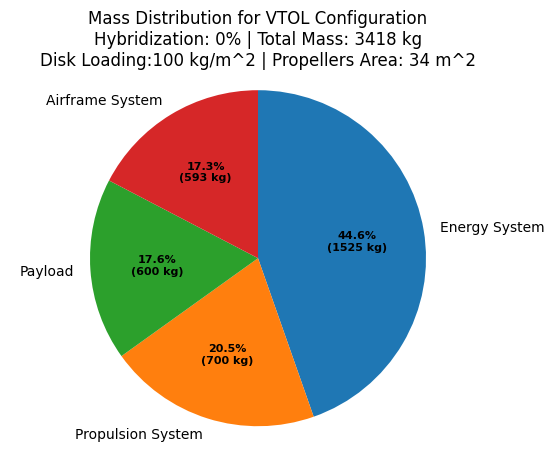

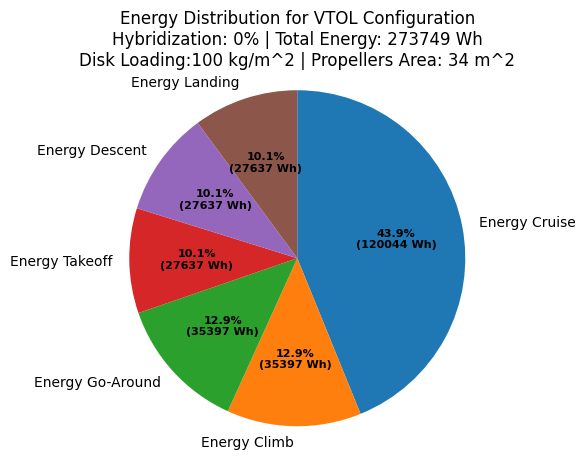

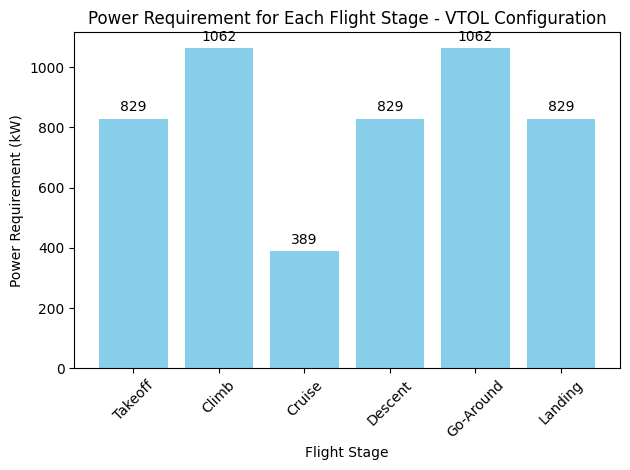

In [4]:
aircraft_config = AircraftConfig(
    aircraft_parameters=aircraft_test_parameters,
    configuration='VTOL',
    hybridization_level=0,  # Fully electric for the test
    payload=600,  # kg
    desired_range=100,  # km
    initial_guess=2630 #kg
)

# Estimate MTOW using fsolve
aircraft_config.solve_for_mtow()

# Now you can safely call visualize_mass_distribution
aircraft_config.calculate_all_masses()
aircraft_config.visualize_mass_distribution()

aircraft_config.calculate_energy_requirements()
aircraft_config.visualize_energy_requirements()

aircraft_config.visualize_power_requirements()